# RiskPY: 0.5.2 vs the development build, as a user would run it

This notebook runs RiskPY the way people actually use it — an options desk pricing a smile,
a risk team computing VaR and ES, a pensions actuary valuing annuities near zero rates, a
reserving actuary running Mack, a capital model, an AI agent calling the tools — and puts the
**published 0.5.2 wheel** next to the **development build** on every scenario.

* Every number is checked against a reference computed **independently of RiskPY** (SciPy,
  closed forms, published values: Mack 1993, AMLCR) — see `cases.py`.
* Each scenario runs in its own fresh interpreter, so a crash or hang in one cannot touch the next.
* *Everyday inputs* (no edge cases) are run through both versions to show nothing regressed.

**Run it** with the kernel from `~/RiskPY/.venv` (the development build installed there).
The 0.5.2 baseline is installed on first use into `~/.cache/riskpy-baseline/0.5.2`
(dependencies are shared with the kernel's environment).

In [1]:
import math, os, sys, time, warnings
sys.path.insert(0, os.path.abspath("."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import cases
import riskpy

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
BASELINE = cases.baseline_path("0.5.2")
refs = cases.references()
print("development build:", os.path.dirname(riskpy.__file__))
print("baseline 0.5.2    :", BASELINE)
print(len(cases.CASES), "scenarios in", len({c.section for c in cases.CASES}), "areas")

development build: ~/RiskPY/.venv/lib/python3.12/site-packages/riskpy
baseline 0.5.2    : ~/.cache/riskpy-baseline/0.5.2
52 scenarios in 9 areas


## 1. Every scenario, both versions

`✅` means the answer matches the independent reference to the stated tolerance, or the call
fails with the right structured error. `❌` says what happened instead.

In [2]:
started = time.perf_counter()
old = cases.run_in(BASELINE)
new = cases.run_in(None)
print(f"ran {2 * len(cases.CASES)} scenario processes in {time.perf_counter() - started:.0f}s")


def shown(outcome):
    if "value" in outcome:
        v = outcome["value"]
        if isinstance(v, float):
            return f"{v:.10g}"
        text = repr(v)
        return text if len(text) < 40 else text[:37] + "..."
    if "timeout" in outcome:
        return f"hung > {outcome['timeout']:.0f}s"
    return f"{outcome['error']} {outcome.get('code') or ''}".strip()


def reference(case):
    e = case.expect
    if "raises" in e:
        return "error " + ("(C++ ValueError)" if e["raises"] == "core" else e["raises"] + "…")
    if "ref" in e:
        r = refs[e["ref"]] if isinstance(e["ref"], str) else e["ref"]
        return f"{r:.10g}" if isinstance(r, float) else (repr(r)[:37] + "...")
    return "finite result"


rows = []
for case, o, n in zip(cases.CASES, old, new):
    v_old, v_new = cases.judge(case, o, refs), cases.judge(case, n, refs)
    rows.append({
        "area": case.section, "scenario": case.label, "reference": reference(case),
        "0.5.2": shown(o), "dev": shown(n),
        "0.5.2 ok": "✅" if v_old == "pass" else "❌ " + v_old,
        "dev ok": "✅" if v_new == "pass" else "❌ " + v_new,
        "the 0.5.2 problem": case.why,
    })
results = pd.DataFrame(rows)

board = (results.assign(old_pass=results["0.5.2 ok"].eq("✅"), new_pass=results["dev ok"].eq("✅"))
         .groupby("area", sort=False)
         .agg(scenarios=("scenario", "size"), **{"0.5.2 passes": ("old_pass", "sum"), "dev passes": ("new_pass", "sum")}))
board.loc["TOTAL"] = board.sum()
board

ran 104 scenario processes in 12s


,scenarios,0.5.2 passes,dev passes
area,,,
Options desk,9,1,9
Market risk,4,1,4
Rates & ALM,7,1,7
Credit,9,2,9
Life & pensions,4,1,4
Reserving,4,2,4
Capital modelling,7,0,7
Statistics,4,0,4
AI agent tools,4,0,4


In [3]:
for area in results["area"].unique():
    display(Markdown(f"### {area}"))
    display(results[results["area"] == area].drop(columns=["area"]).set_index("scenario"))

### Options desk

,reference,0.5.2,dev,0.5.2 ok,dev ok,the 0.5.2 problem
scenario,,,,,,
"ATM call, the textbook number",10.45058357,10.45058357,10.45058357,✅,✅,
"Far OTM put (30% strike, 6m) — a tail-hedging wing",7.468801161e-18,0,7.468801161e-18,❌ off by 1.0e+00 rel,✅,erf-based N(x) rounded the price to exactly 0
Deep OTM call (3× strike),1.212090808e-14,1.110223025e-14,1.212090808e-14,❌ off by 8.4e-02 rel,✅,
Implied vol of a cheap 2× strike call,0.2,0.156250001,0.2,❌ off by 2.2e-01 rel,✅,absolute 1e-8 price tolerance stopped at the first midpoint
Implied vol at 2000% vol (price ≡ S),error RP30…,15,ConvergenceError RP302,❌ no error (returned 15.000000000250001),✅,returned 15.0 with no error
Zero-vol forward: delta of a call whose forward is OTM,0,1,0,❌ off by 1.0e+00,✅,"delta decided by S vs K, not the forward"
Zero-vol forward: theta per day,-0.01290023466,0,-0.01290023466,❌ off by 1.0e+00 rel,✅,
Heston at expiry is intrinsic,0,-0.1641784037,0,❌ off by 1.6e-01,✅,quadrature error gave a negative price
NaN spot from a bad market-data feed,error RP101…,'nan',InputError RP101,❌ no error (returned 'nan'),✅,returned nan silently


### Market risk

,reference,0.5.2,dev,0.5.2 ok,dev ok,the 0.5.2 problem
scenario,,,,,,
ES of an empty P&L vector,error RP111…,IndexError,InputError RP111,❌ IndexError,✅,raw IndexError
ES with level given as a percentage-ish 1.5,error RP110…,ValueError,InputError RP110,❌ ValueError,✅,
Parametric VaR with a negative sd,error RP102…,-0.2326347874,InputError RP102,❌ no error (returned -0.23263478740408414),✅,returned a negative VaR
Historical ES ≥ VaR on fat-tailed returns,finite result,True,True,✅,✅,


### Rates & ALM

...

,reference,0.5.2,dev,0.5.2 ok,dev ok,the 0.5.2 problem
scenario,,,,,,
ES₉₅ of a 1%-likely loss of 100 (Acerbi–Tasche = 20),20,1.0055,20.11,❌ off by 9.5e-01 rel,✅,averaged the tied zeros: 1.0
"Health claims, NB dispersion 0.3: mean count",10,8.964096667,10.00475877,❌ off by 1.0e-01 rel,✅,r = 1/d truncated to an int: 8.97
"Health claims, NB dispersion 2: mean count",10,0,9.988917069,❌ off by 1.0e+00 rel,✅,all zeros
"FFT compound Poisson λ=50, default grid: mean",50,7.447269826,50,❌ off by 8.5e-01 rel,✅,wrapped around: 7.45
"Loss elimination ratio, CV 2, deductible 2× mean",0.7026855974,0.7933019057,0.7026855974,❌ off by 1.3e-01 rel,✅,not a lognormal LER: 0.793
"Loss elimination ratio, CV 0.5, deductible = mean",0.8132849568,0.87960009,0.8132849568,❌ off by 8.2e-02 rel,✅,
Credibility with a NaN k (bad config),error (C++ ValueError),1,ValueError,❌ no error (returned 1.0),✅,returned full credibility 1.0


### Statistics

,reference,0.5.2,dev,0.5.2 ok,dev ok,the 0.5.2 problem
scenario,,,,,,
χ² CDF at 10⁶ degrees of freedom,0.5001880632,0.4216075981,0.5001880632,❌ off by 1.6e-01 rel,✅,iteration cap: 0.42 for 0.50
"Student-t 1e-20 quantile, df=5",-15683.92545,-4096,-15683.92545,❌ off by 7.4e-01 rel,✅,-4096 for -15684
"Incomplete gamma P(1e5, 1e5)",0.5004205221,0.4996293208,0.5004205221,❌ off by 1.6e-03 rel,✅,
Normal quantile at p = 1e-320,-38.26912534,OverflowError,-38.26912534,❌ OverflowError: math range error,✅,


### AI agent tools

,reference,0.5.2,dev,0.5.2 ok,dev ok,the 0.5.2 problem
scenario,,,,,,
aggregate_loss with trials sent as 1000.0 (JSON numbers),finite result,TypeError,1993.327869,❌ TypeError: __init__(): incompatible constructor arguments. The f...,✅,pybind refused 1000.0
bootstrap_yield_curve with frequency 100000,error RP405…,hung > 8s,InputError RP405,❌ timed out after 8s,✅,ran for minutes
convert_rate with 10¹⁶ periods a year,error RP405…,0,InputError RP405,❌ no error (returned 0.0),✅,returned 0.0
bond_analytics on a 1e308 face value,error RP304…,"{'price': 1.0000000000000014e+308, 'm...",InputError RP304,"❌ no error (returned {'price': 1.0000000000000014e+308, 'm...)",✅,'ok' with null durations


## 2. Regression check: everyday inputs

Ordinary, in-range calls — 60 options, 30 discount factors / IRB exposures / Merton firms /
CDS contracts, the SULT at 14 ages, the Taylor–Ashe triangle. Nothing here is an edge case,
so the two versions should agree to rounding. Where they differ on purpose, the table says why.

In [4]:
every_new = cases.value_in(None, cases.EVERYDAY)
every_old = cases.value_in(BASELINE, cases.EVERYDAY)
expected_change = {
    "cds_par_spread": "exact accrual on default (0.5.2 used a midpoint rule); the dev values match a quadrature reference",
}
rows = []
for group, new_vals in every_new.items():
    old_vals = every_old[group]
    if group.startswith("implied_vol error"):
        rows.append({"group": group, "values": len(new_vals),
                     "max |0.5.2 − dev| (relative)": "—",
                     "0.5.2 worst |iv − σ|": f"{max(map(abs, old_vals)):.1e}",
                     "dev worst |iv − σ|": f"{max(map(abs, new_vals)):.1e}",
                     "verdict": "dev more accurate"})
        continue
    diff = max(abs(a - b) / max(abs(b), 1e-300) for a, b in zip(new_vals, old_vals))
    rows.append({"group": group, "values": len(new_vals), "max |0.5.2 − dev| (relative)": f"{diff:.1e}",
                 "0.5.2 worst |iv − σ|": "", "dev worst |iv − σ|": "",
                 "verdict": "identical to rounding" if diff < 1e-12 else expected_change.get(group, "CHANGED — investigate")})
everyday = pd.DataFrame(rows).set_index("group")
everyday

,values,max |0.5.2 − dev| (relative),0.5.2 worst |iv − σ|,dev worst |iv − σ|,verdict
group,,,,,
black_scholes + greeks,360,1.6e-14,,,identical to rounding
implied_vol error (iv - true sigma),60,—,8.3e-09,1.8e-11,dev more accurate
discount_factor,30,2.9e-14,,,identical to rounding
basel_irb_capital,30,4.7e-16,,,identical to rounding
merton pd,30,0.0e+00,,,identical to rounding
cds_par_spread,30,2.9e-05,,,exact accrual on default (0.5.2 used a midpoint rule); the dev val...
life annuities & reserves,56,1.1e-15,,,identical to rounding
chain ladder & Mack,29,0.0e+00,,,identical to rounding


## 3. Speed of the everyday calls

Microseconds per call (one process each, same machine, back to back). The edge-case fixes
added input checks and tighter tolerances; this is what they cost on ordinary inputs.

In [5]:
t_new = cases.value_in(None, cases.TIMING)
t_old = cases.value_in(BASELINE, cases.TIMING)
timing = pd.DataFrame({"0.5.2 µs": t_old, "dev µs": t_new})
timing["dev / 0.5.2"] = timing["dev µs"] / timing["0.5.2 µs"]
timing.round(2)

,0.5.2 µs,dev µs,dev / 0.5.2
black_scholes,0.39,0.50,1.26
greeks,1.49,1.53,1.03
implied_vol,13.45,22.48,1.67
cds_par_spread,6.01,30.75,5.11
merton,1.27,1.76,1.38
basel_irb_capital,1.92,1.95,1.01
whole_life_annuity_due,2.34,2.31,0.99
"gammainc(50, 49)",2.92,2.95,1.01
"t_ppf(0.01, 5)",24.31,28.99,1.19
"chi2_ppf(0.95, 10)",14.61,10.87,0.74


## 4. How a user runs it

### 4a. Options desk: a full volatility smile, wings included

Price a 20%-vol smile from 25% to 400% of spot with Black–Scholes, then recover the vols with
`implied_vol` — the round trip every vol desk runs. 0.5.2's absolute price tolerance gave up in
the cheap wings; its `erf`-based normal CDF priced the far puts at 0.

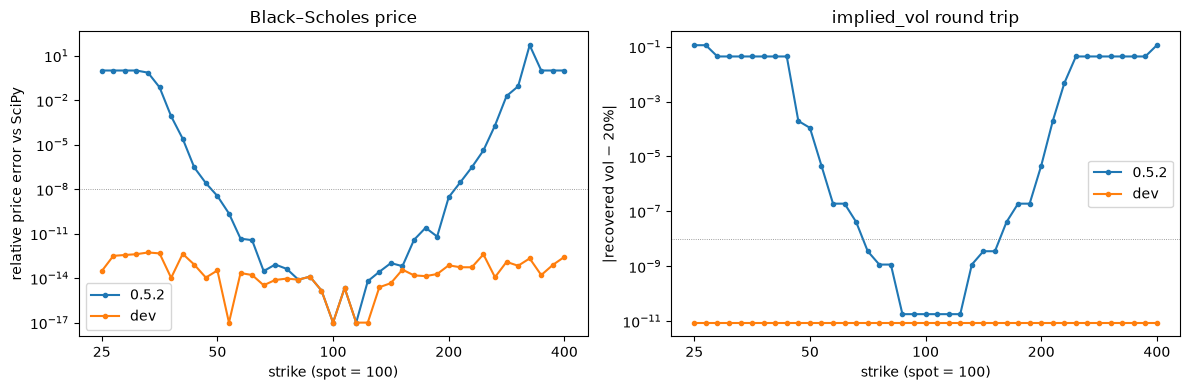

strikes where implied_vol is more than 1e-6 off or fails:
  0.5.2: 23 of 41
  dev  : 0 of 41


In [6]:
strikes = [float(k) for k in np.geomspace(25, 400, 41)]
smile_code = f'''
from riskpy.quant import black_scholes, implied_vol
out = []
for K in {strikes!r}:
    kind = "put" if K < 100 else "call"
    p = black_scholes(100, K, 0.5, 0.02, 0.2, kind=kind)
    try:
        out.append([p, implied_vol(p, 100, K, 0.5, 0.02, kind=kind)])
    except Exception as exc:
        out.append([p, type(exc).__name__])
result = out
'''
smile_old, smile_new = cases.value_in(BASELINE, smile_code), cases.value_in(None, smile_code)


def vol_error(rows):
    return [abs(iv - 0.2) if isinstance(iv, float) else np.nan for _, iv in rows]


def price_error(rows, kinds):
    return [abs(p - cases.bs_ref(100, K, 0.5, 0.02, 0.2, kind=k)) / cases.bs_ref(100, K, 0.5, 0.02, 0.2, kind=k)
            for (p, _), K, k in zip(rows, strikes, kinds)]


kinds = ["put" if K < 100 else "call" for K in strikes]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for rows, label in ((smile_old, "0.5.2"), (smile_new, "dev")):
    axes[0].semilogy(strikes, np.maximum(price_error(rows, kinds), 1e-17), "o-", ms=3, label=label)
    axes[1].semilogy(strikes, np.maximum(vol_error(rows), 1e-17), "o-", ms=3, label=label)
axes[0].set(xscale="log", xlabel="strike (spot = 100)", ylabel="relative price error vs SciPy",
            title="Black–Scholes price")
axes[1].set(xscale="log", xlabel="strike (spot = 100)", ylabel="|recovered vol − 20%|",
            title="implied_vol round trip")
for ax in axes:
    ax.axhline(1e-8, color="grey", lw=0.6, ls=":")
    ax.set_xticks([25, 50, 100, 200, 400], ["25", "50", "100", "200", "400"])
    ax.minorticks_off()
    ax.legend()
plt.tight_layout()
plt.show()

print("strikes where implied_vol is more than 1e-6 off or fails:")
print("  0.5.2:", sum(not (isinstance(iv, float) and abs(iv - 0.2) < 1e-6) for _, iv in smile_old), "of", len(strikes))
print("  dev  :", sum(not (isinstance(iv, float) and abs(iv - 0.2) < 1e-6) for _, iv in smile_new), "of", len(strikes))

### 4b. Credit: CDS spreads from investment grade to defaulting

Par spread for a flat hazard from 0.1% to 50 a year (R = 40%, r = 3%, 5y quarterly), against an
exact integral of protection and accrued premium (`cases.cds_ref`).

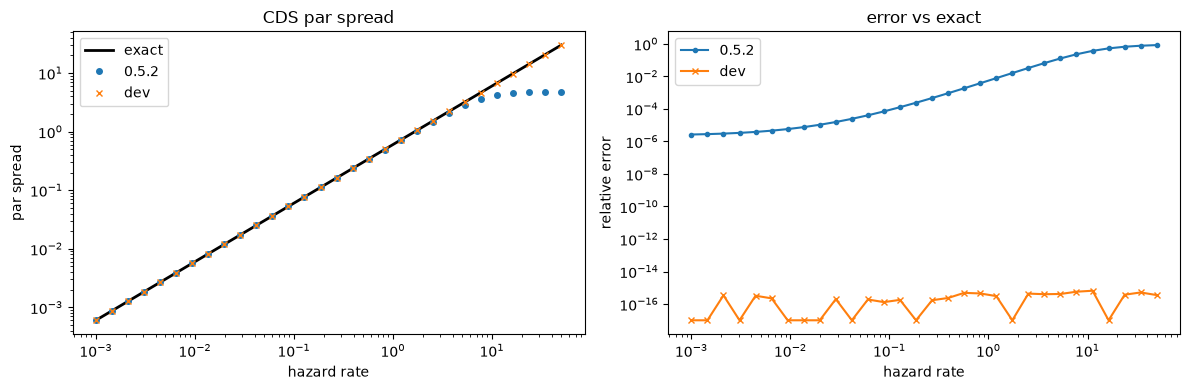

In [7]:
hazards = [float(h) for h in np.geomspace(1e-3, 50, 30)]
cds_code = f'''
from riskpy.credit import cds_par_spread
result = [cds_par_spread(h, 0.4, 0.03, 5) for h in {hazards!r}]
'''
cds_old, cds_new = cases.value_in(BASELINE, cds_code), cases.value_in(None, cds_code)
exact = [cases.cds_ref(h, 0.4, 0.03, 5) for h in hazards]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(hazards, exact, "k-", lw=2, label="exact")
ax[0].loglog(hazards, cds_old, "o", ms=4, label="0.5.2")
ax[0].loglog(hazards, cds_new, "x", ms=5, label="dev")
ax[0].set(xlabel="hazard rate", ylabel="par spread", title="CDS par spread")
ax[1].loglog(hazards, [abs(a - e) / e for a, e in zip(cds_old, exact)], "o-", ms=3, label="0.5.2")
ax[1].loglog(hazards, [max(abs(a - e) / e, 1e-17) for a, e in zip(cds_new, exact)], "x-", ms=4, label="dev")
ax[1].set(xlabel="hazard rate", ylabel="relative error", title="error vs exact")
for a in ax:
    a.legend()
plt.tight_layout()
plt.show()

### 4c. Capital model: a compound Poisson–lognormal book

Frequency Poisson(2), severity mean 1,000 and sd 2,000 on the money scale. The aggregate is
a **sum of N independent claims**, so its moments are E = λ·E[X] = 2,000 and
sd = √(λ·E[X²]) = √(2 × 5,000,000) = 3,162.

The formula `claim_count * severity` — the pattern in the README's first example — is **not**
that: it multiplies one claim size by the count, so every claim in a year is the same size and
the tail is overstated. The C++ `simulate_aggregate_loss` (and the `aggregate_loss` tool) draw
N claims; the FFT recursion on a discretised severity is an independent check.

In [8]:
from riskpy.mc import simulate, Poisson, LogNormal, Bernoulli, Constant

sev = LogNormal.from_moments(1000, 2000)
mu, sigma = sev.mu, sev.sigma
theory_mean, theory_sd = 2 * 1000, math.sqrt(2 * (1000**2 + 2000**2))

naive = simulate(lambda n, s: n * s, 200_000, seed=42, n=Poisson(2.0), s=sev)
compound = np.asarray(riskpy.MonteCarloSimulator(200_000, 42).simulate_aggregate_loss(2.0, mu, sigma))

grid_step = 25.0
edges = np.arange(0, 400_000 + grid_step, grid_step)
cdf = np.array([sev.cdf(x + grid_step / 2) for x in edges])
pmf = np.diff(np.concatenate([[0.0], cdf]))
agg = np.asarray(riskpy.FourierTransform.compound_poisson_pmf(list(pmf), 2.0))
k = np.arange(agg.size) * grid_step
fft_mean = float((k * agg).sum())
fft_sd = math.sqrt(float((k * k * agg).sum()) - fft_mean**2)
fft_var995 = float(k[np.searchsorted(np.cumsum(agg), 0.995)])

compare = pd.DataFrame({
    "theory": [theory_mean, theory_sd, np.nan],
    "naive N × X (simulate)": [naive.mean, naive.std, naive.var(0.995)],
    "compound Σ X (C++ core)": [compound.mean(), compound.std(), float(np.quantile(compound, 0.995))],
    "FFT recursion": [fft_mean, fft_sd, fft_var995],
}, index=["mean", "sd", "VaR 99.5%"]).round(0)
display(compare)

# Point mass: a 1-in-100 total loss of 100. Expected shortfall at 95% is 100 × 0.01 / 0.05 = 20.
atom = simulate(lambda ev, sev: ev * sev, 200_000, seed=1, ev=Bernoulli(0.01), sev=Constant(100.0))
print(f"atom: VaR95 = {atom.var(0.95):.1f}, ES95 = {atom.tvar(0.95):.2f} (theory 20; 0.5.2 reported 1.0)")

,theory,naive N × X (simulate),compound Σ X (C++ core),FFT recursion
mean,2000.0,2001.0,1994.0,2000.0
sd,3162.0,5128.0,3127.0,3158.0
VaR 99.5%,NaN,28195.0,18223.0,18200.0


atom: VaR95 = 0.0, ES95 = 20.11 (theory 20; 0.5.2 reported 1.0)


### 4d. Reserving: Mack on the Taylor–Ashe triangle, then a bootstrap

In [9]:
from riskpy import reserving

tri = reserving.genins()
mack = reserving.mack_chain_ladder(tri)
table = pd.DataFrame({"reserve": np.round(mack.reserve, 0), "Mack s.e.": np.round(mack.se, 0)},
                     index=list(tri.origin) if hasattr(tri, "origin") else None)
display(table.T)
print(f"total reserve {float(np.sum(mack.reserve)):,.0f} (Mack 1993: 18,680,856); "
      f"total s.e. {mack.total_se:,.0f} (2,447,095)")

boot = reserving.bootstrap_chain_ladder(tri, n=2000, seed=7)
print(f"bootstrap: mean total {np.mean(boot.total):,.0f}, 99.5th pct {np.percentile(boot.total, 99.5):,.0f}")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    flat = reserving.bootstrap_chain_ladder([[10, 20, 30, 40], [20, 40, 60], [30, 60], [40]], n=200, seed=1)
print("proportional triangle bootstrap (0.5.2: all NaN):", sorted({float(v) for v in np.round(flat.total, 6)})[:3])

,0,1,2,3,4,5,6,7,8,9
reserve,0.0,94634.0,469511.0,709638.0,984889.0,1419459.0,2177641.0,3920301.0,4278972.0,4625811.0
Mack s.e.,0.0,75535.0,121699.0,133549.0,261406.0,411010.0,558317.0,875328.0,971258.0,1363155.0


total reserve 18,680,856 (Mack 1993: 18,680,856); total s.e. 2,447,095 (2,447,095)
bootstrap: mean total 18,927,187, 99.5th pct 29,000,079
proportional triangle bootstrap (0.5.2: all NaN): [200.0]


### 4e. An AI agent calling the tools

Agents send JSON: whole numbers arrive as floats, percentages turn up where decimals belong,
and an upstream NaN is a string away. Each call returns either strict JSON or a structured
error the agent can act on.

In [10]:
from riskpy import tools

calls = [
    ("black_scholes", {"S": 100, "K": 105, "T": 0.5, "r": 0.03, "sigma": 0.2}),
    ("black_scholes", {"S": 100, "K": 105, "T": 0.5, "r": 0.03, "sigma": 20}),     # 20 for 20%
    ("aggregate_loss", {"expected_frequency": 2, "severity_mean": 1000, "severity_sd": 2000,
                        "trials": 50000.0, "seed": 3.0}),                           # JSON floats
    ("bootstrap_yield_curve", {"par_rates": [0.03, 0.035], "maturities": [1, 2], "frequency": 100000}),
    ("bond_analytics", {"face": 1e308, "coupon": 0.05, "maturity": 10, "ytm": 0.05}),
    ("convert_rate", {"rate": 0.05, "from_compounding": "monthly", "to_compounding": "continuous"}),
]
for name, args in calls:
    out = tools.call(name, args, errors="return")
    if isinstance(out, dict) and "error" in out:
        e = out["error"]
        print(f"{name:<22} → {e['code']} ({e.get('param')}): {e['message'][:90]}")
    else:
        text = repr(out if not isinstance(out, dict) else {k: out[k] for k in list(out)[:4]})
        print(f"{name:<22} → {text[:110]}")

black_scholes          → 4.178299715513496
black_scholes          → RP105 (sigma): sigma = 20 looks like a percentage: volatility is a decimal, so sigma must be at most 5 (5
aggregate_loss         → {'trials': 50000, 'mean': 1991.4710793271395, 'std': 3144.2448781407247, 'min': 0.0}
bootstrap_yield_curve  → RP405 (maturities): maturity × frequency = 400000 payment periods; the tool accepts at most 100000
bond_analytics         → RP304 (None): result.macaulay_duration is inf: an intermediate value overflowed double precision
convert_rate           → 0.04989612178396426


## 5. Verdict

In [11]:
dev_fail = results[results["dev ok"] != "✅"]
old_fail = results[results["0.5.2 ok"] != "✅"]
regressions = results[(results["0.5.2 ok"] == "✅") & (results["dev ok"] != "✅")]
changed = everyday[everyday["verdict"].str.startswith("CHANGED")]
print(f"scenarios: {len(results)} | 0.5.2 fails {len(old_fail)} | dev fails {len(dev_fail)} | "
      f"regressions {len(regressions)}")
print(f"everyday groups that changed unexpectedly: {len(changed)}")
print(f"slowest relative to 0.5.2: {timing['dev / 0.5.2'].idxmax()} at {timing['dev / 0.5.2'].max():.1f}×")
assert dev_fail.empty and regressions.empty and changed.empty

scenarios: 52 | 0.5.2 fails 44 | dev fails 0 | regressions 0
everyday groups that changed unexpectedly: 0
slowest relative to 0.5.2: cds_par_spread at 5.1×
